# Mapping lineage-specific enhancers at the *BCL11A* locus

The transcription factor **BCL11A** represses fetal hemoglobin ($\text{HbF}$) expression during adult erythropoiesis, making its erythroid-specific intronic enhancers (`+55 kb`, `+58 kb`, and `+62 kb` downstream of the minus-strand transcription start site) prime therapeutic targets in $\beta$-hemoglobinopathies ([Bauer et al., *Science* 2013](https://doi.org/10.1126/science.1242088); [Canver et al., *Nature* 2015](https://doi.org/10.1038/nature15521)).

In this tutorial, we use AlphaGenome 2's input gradient API (`predict_interval_gradients_batch`) and the `alphagenome.interpretation.enhancer_scoring` module to:

1. **Call and visualize *de novo* enhancers per lineage** using `enhancer_scoring.get_active_enhancers`, `plot_components.EnhancerArcs`, and `plot_components.Tracks`, recovering the erythroid-specific intronic enhancer cluster (`+55 kb`, `+58 kb`, `+62 kb`) alongside lineage-specific regulatory elements across hematopoietic differentiation.
2. **Reconcile *de novo* calls into consensus enhancers across lineages** with `enhancer_scoring.assign_consensus_enhancers` to quantify cell-type specificity and compare enhancer activity side by side across biosamples.
3. **Score fixed candidate regulatory elements** directly across lineages without threshold censoring using `enhancer_scoring.score_enhancers`.

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

## Set up, gene annotation, and hematopoietic conditions

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)). We initialize the AlphaGenome 2 client (`dna_client.create`), load GENCODE v46 (GRCh38) annotations (`gtf`), and construct a `TranscriptExtractor` filtered to MANE Select transcripts (`gene_annotation.filter_to_mane_select_transcript(gtf)`). We then define 8 hematopoietic differentiation conditions spanning stem/progenitor, erythroid, myeloid, and lymphoid lineages.

In [2]:
# @title Imports and client initialization
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import track_data
from alphagenome.data import transcript
from alphagenome.interpretation import enhancer_scoring
from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import dna_output
from alphagenome.visualization import plot_components
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

dna_model = dna_client.create(colab_utils.get_api_key())

gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf_mane = gene_annotation.filter_to_mane_select_transcript(gtf)
transcript_extractor = transcript.TranscriptExtractor(gtf_mane)

BCL11A_GENE_ID = 'ENSG00000119866'

In [3]:
# @title Define hematopoietic differentiation lineages
HEMATOPOIETIC_LINEAGES = {
    'HSC': 'UBERON:0002371_CL:0000037',
    'MEP': 'UBERON:0002371_CL:0000050',
    'Proerythroblast': 'UBERON:0002371_CL:0000547',
    'Erythroid': 'UBERON:0002371_CL:0000765',
    'GMP': 'UBERON:0002371_CL:0000557',
    'Monocyte': 'UBERON:0002371_CL:0001054',
    'B cell': 'UBERON:0002371_CL:0000788',
    'T cell': 'UBERON:0002371_CL:0000895',
}

supported_df = dna_model.supported_conditions()
pd.DataFrame(
    list(HEMATOPOIETIC_LINEAGES.items()), columns=['lineage', 'condition']
).merge(
    supported_df[
        ['condition', 'biosample_name', 'sc_gene_expression', 'sc_atac']
    ],
    on='condition',
    how='left',
)

,lineage,condition,biosample_name,sc_gene_expression,sc_atac
0,HSC,UBERON:0002371_CL:0000037,bone marrow hematopoietic stem cell,observed,observed
1,MEP,UBERON:0002371_CL:0000050,bone marrow megakaryocyte-erythroid progenitor...,observed,observed
2,Proerythroblast,UBERON:0002371_CL:0000547,bone marrow proerythroblast,observed,observed
3,Erythroid,UBERON:0002371_CL:0000765,bone marrow erythroblast,observed,observed
4,GMP,UBERON:0002371_CL:0000557,bone marrow granulocyte monocyte progenitor cell,observed,observed
5,Monocyte,UBERON:0002371_CL:0001054,bone marrow CD14-positive monocyte,observed,observed
6,B cell,UBERON:0002371_CL:0000788,bone marrow naive B cell,observed,observed
7,T cell,UBERON:0002371_CL:0000895,"bone marrow naive thymus-derived CD4-positive,...",observed,observed


## Calling and visualizing active enhancers across lineages

To discover active enhancers *de novo* from sequence gradients and chromatin accessibility (see the [Enhancer scoring API reference](https://www.alphagenomedocs.com/api/interpretation.html#enhancer-scoring) for algorithm and parameter details):

1. **Predict input gradients and chromatin accessibility**: Query `dna_model.predict_interval_gradients_batch` (`OutputType.SC_GENE_EXPRESSION`) and `dna_model.predict_intervals` (`OutputType.SC_ATAC`) across the 8 lineages over the 1 Mb interval centered on *BCL11A*'s median TSS.
2. **Call active enhancers per lineage (`enhancer_scoring.get_active_enhancers`)**: Score sliding-window tiles by smoothed input gradients and chromatin accessibility, filter by calibrated activity thresholds, and extract local-maximum enhancer summits independently in each lineage.

In [4]:
# @title Predict and call BCL11A enhancers across 8 hematopoietic lineages
lineage_conditions = list(HEMATOPOIETIC_LINEAGES.values())
lineage_labels = list(HEMATOPOIETIC_LINEAGES.keys())

grad_outputs = dna_model.predict_interval_gradients_batch(
    gene_ids=BCL11A_GENE_ID,
    requested_output=dna_output.OutputType.SC_GENE_EXPRESSION,
    sequence_length=dna_client.SEQUENCE_LENGTH_1MB,
    conditions=lineage_conditions,
)
atac_outputs = dna_model.predict_intervals(
    intervals=[g.interval for g in grad_outputs],
    conditions=lineage_conditions,
    requested_outputs=[dna_output.OutputType.SC_ATAC],
)

enhancers_df = enhancer_scoring.get_active_enhancers(
    grad_outputs,
    gtf=gtf,
    accessibility_outputs=atac_outputs,
)

erythroid_idx = lineage_labels.index('Erythroid')
erythroid_biosample = grad_outputs[erythroid_idx].biosample_name
erythroid_enhancers = enhancers_df[
    enhancers_df['biosample_name'] == erythroid_biosample
].sort_values('gradient_score', ascending=False)

bcl11a_tss = int(enhancers_df['tss'].iloc[0])
print(
    f'Called {len(enhancers_df)} enhancer-gene links across lineages '
    f'({len(erythroid_enhancers)} in Erythroid; '
    f'BCL11A TSS = chr2:{bcl11a_tss:,}).'
)
erythroid_enhancers[[
    'chromosome',
    'start',
    'end',
    'tss',
    'tss_distance',
    'gradient_score',
    'atac_score',
]]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Called 93 enhancer-gene links across lineages (10 in Erythroid; BCL11A TSS = chr2:60,553,654).


,chromosome,start,end,tss,tss_distance,gradient_score,atac_score
28,chr2,60498119,60498619,60553654,55285.0,0.032775,73.164040
27,chr2,60495119,60495619,60553654,58285.0,0.011873,31.914005
26,chr2,60490619,60491119,60553654,62785.0,0.010099,46.149357
33,chr2,60553369,60553869,60553654,35.0,0.004095,12.513713
29,chr2,60504119,60504619,60553654,49285.0,0.003391,7.021736
25,chr2,60473619,60474119,60553654,79785.0,0.003296,9.859783
31,chr2,60550119,60550619,60553654,3285.0,0.002451,38.764313
32,chr2,60551869,60552369,60553654,1535.0,0.001723,16.537992
24,chr2,60439619,60440119,60553654,113785.0,0.001471,14.912198
30,chr2,60525619,60526119,60553654,27785.0,0.001336,1.424859


In the table above, the highest-scoring erythroid enhancers lie ~55–62 kb from the *BCL11A* TSS and overlap the three experimentally validated erythroid DHS elements (`+55 kb` at `chr2:60,497,676-60,498,941`, `+58 kb` at `chr2:60,494,920-60,496,208`, and `+62 kb` at `chr2:60,490,409-60,491,729`).

Next, we pass `enhancers_df` to `plot_components.EnhancerArcs` alongside `|GradxInput|` and `scATAC` `plot_components.Tracks` to visualize these enhancer-to-gene links across four representative hematopoietic branches (`HSC`, `Erythroid`, `Monocyte`, and `B cell`):

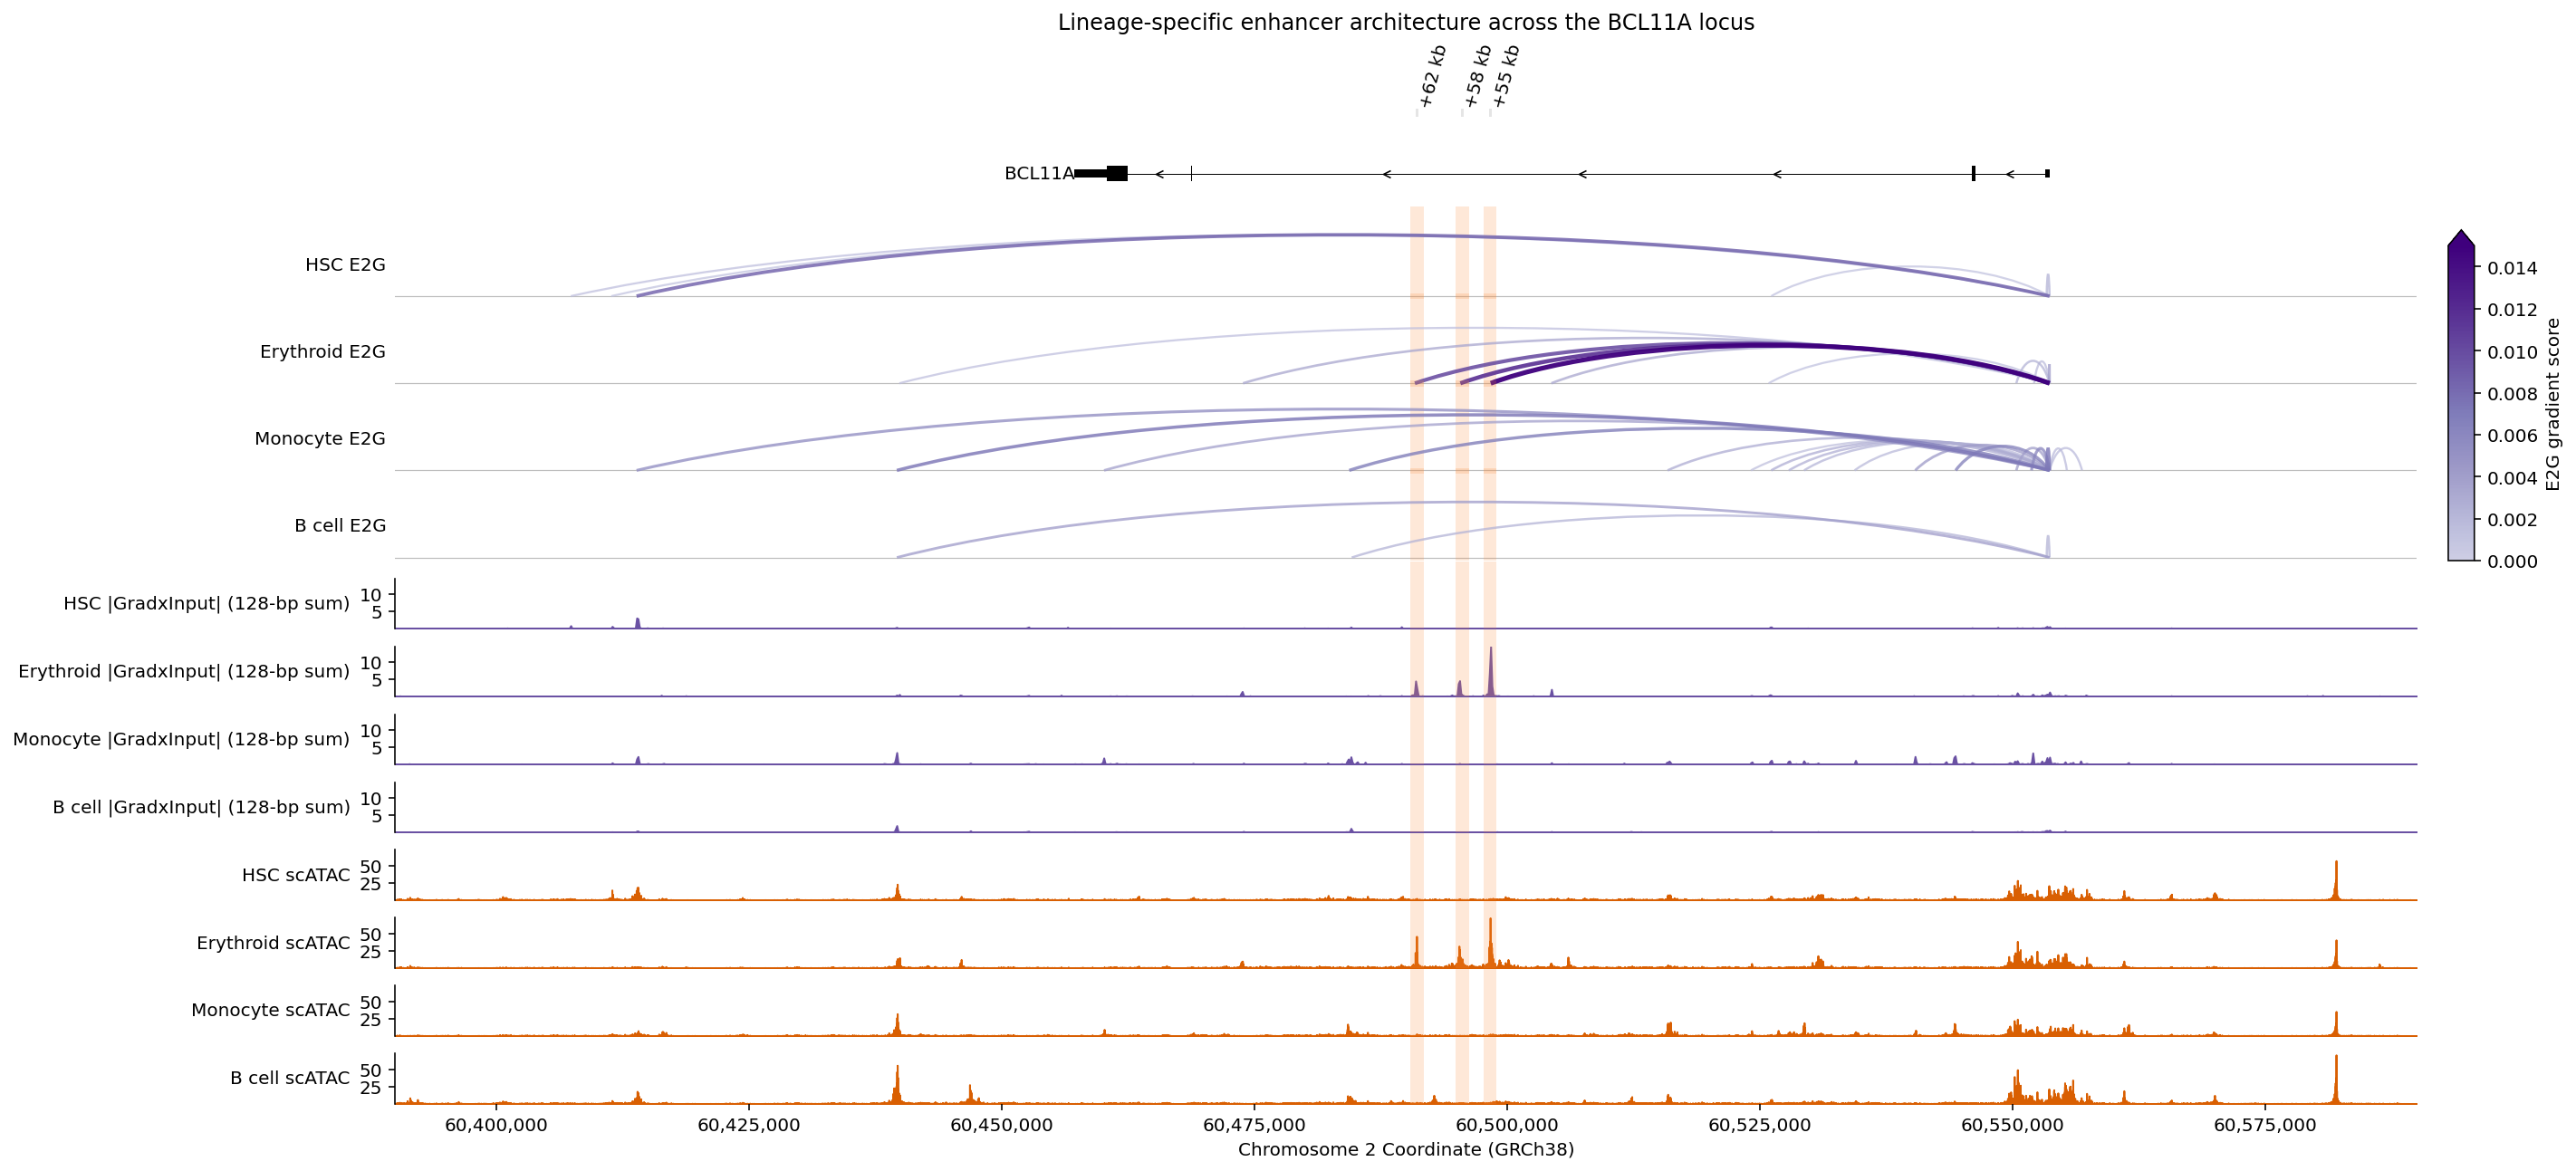

In [5]:
# @title Plot multi-lineage E2G arcs and tracks at the BCL11A locus
plot_interval = genome.Interval('chr2', 60_390_000, 60_590_000)
plot_lineages = ['HSC', 'Erythroid', 'Monocyte', 'B cell']
plot_indices = [lineage_labels.index(lineage) for lineage in plot_lineages]

arc_vmin, arc_vmax = 0.0, 0.015
arc_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    'e2g_purples', plt.get_cmap('Purples')(np.linspace(0.3, 1.0, 256))
)
arc_components = [
    plot_components.EnhancerArcs(
        enhancers_df[
            enhancers_df['biosample_name'] == grad_outputs[idx].biosample_name
        ],
        ylabel=f'{lineage} E2G',
        fig_height=0.9,
        cmap=arc_cmap,
        vmin=arc_vmin,
        vmax=arc_vmax,
        alpha_range=(0.7, 0.95),
    )
    for lineage, idx in zip(plot_lineages, plot_indices, strict=True)
]
grad_tracks = track_data.concat([
    grad_outputs[idx].to_track_data(name=lineage).downsample(128)
    for lineage, idx in zip(plot_lineages, plot_indices, strict=True)
])
atac_tracks = track_data.concat([
    atac_outputs[idx]
    .filter_to_observed()
    .sc_atac.select_tracks_by_index([0])
    .with_metadata_column('name', lineage)
    for lineage, idx in zip(plot_lineages, plot_indices, strict=True)
])

# Highlight the canonical +62 kb, +58 kb, and +55 kb erythroid enhancers.
canonical_erythroid_dhs = [
    genome.Interval('chr2', 60_490_409, 60_491_729, name='+62 kb'),
    genome.Interval('chr2', 60_494_920, 60_496_208, name='+58 kb'),
    genome.Interval('chr2', 60_497_676, 60_498_941, name='+55 kb'),
]

fig = plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(
            transcript_extractor.extract(plot_interval)
        ),
        *arc_components,
        plot_components.Tracks(
            grad_tracks,
            filled=True,
            shared_y_scale=True,
            track_colors='#6a51a3',
            ylabel_template='{name} |GradxInput| (128-bp sum)',
            track_height=0.65,
        ),
        plot_components.Tracks(
            atac_tracks,
            filled=True,
            shared_y_scale=True,
            track_colors='#d95f02',
            ylabel_template='{name} scATAC',
            track_height=0.65,
        ),
    ],
    interval=plot_interval,
    annotations=[
        plot_components.IntervalAnnotation(
            canonical_erythroid_dhs,
            labels=['+62 kb', '+58 kb', '+55 kb'],
            colors='#fd8d3c',
            alpha=0.2,
            label_angle=75,
        )
    ],
    title='Lineage-specific enhancer architecture across the BCL11A locus',
    xlabel='Chromosome 2 Coordinate (GRCh38)',
)
fig.axes[-1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)
top_arc_pos = fig.axes[2].get_position()
bot_arc_pos = fig.axes[5].get_position()
cbar_ax = fig.add_axes([
    top_arc_pos.x1 + 0.012,
    bot_arc_pos.y0,
    0.01,
    top_arc_pos.y1 - bot_arc_pos.y0,
])
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=mpl.colors.Normalize(vmin=arc_vmin, vmax=arc_vmax),
        cmap=arc_cmap,
    ),
    cax=cbar_ax,
    extend='max',
)
cbar.set_label('E2G gradient score')
plt.show()

## Comparing *de novo* calls across lineages with consensus enhancers

In the locus plot above, several regulatory elements—such as the *BCL11A* promoter near `chr2:60.55 Mb` and distal elements near `chr2:60.44 Mb`—are called across multiple lineages. However, if we want to build an **enhancer × lineage activity table** or count **in how many lineages each enhancer is active**, grouping `enhancers_df` by raw `(start, end)` coordinates splits shared biological elements whenever independent per-lineage summits land on adjacent 250 bp-offset tiles:

- **`+58 kb` enhancer**: `MEP` and `Proerythroblast` peak at `chr2:60,494,869-60,495,369`, whereas `Erythroid` peaks one 250 bp step away at `chr2:60,495,119-60,495,619`—splitting the `0.0055 → 0.0096 → 0.0119` erythroid differentiation ramp across two incomplete rows if pivoted on `(start, end)`.
- ***BCL11A* promoter**: `Erythroid` peaks at `chr2:60,553,369-60,553,869` while the other 7 lineages peak at `chr2:60,553,119-60,553,619`, making a pan-lineage (`8/8`) element look split.

Calling `enhancer_scoring.assign_consensus_enhancers` clusters mutually overlapping per-gene calls (`min_reciprocal_overlap=0.5`) into shared `(consensus_peak_start, consensus_peak_end)` coordinates so we can count lineage specificity (`n_lineages`) and compare *de novo* enhancer activity side by side:

Merged 52 distinct intervals into 41 consensus peaks across 8 lineages.


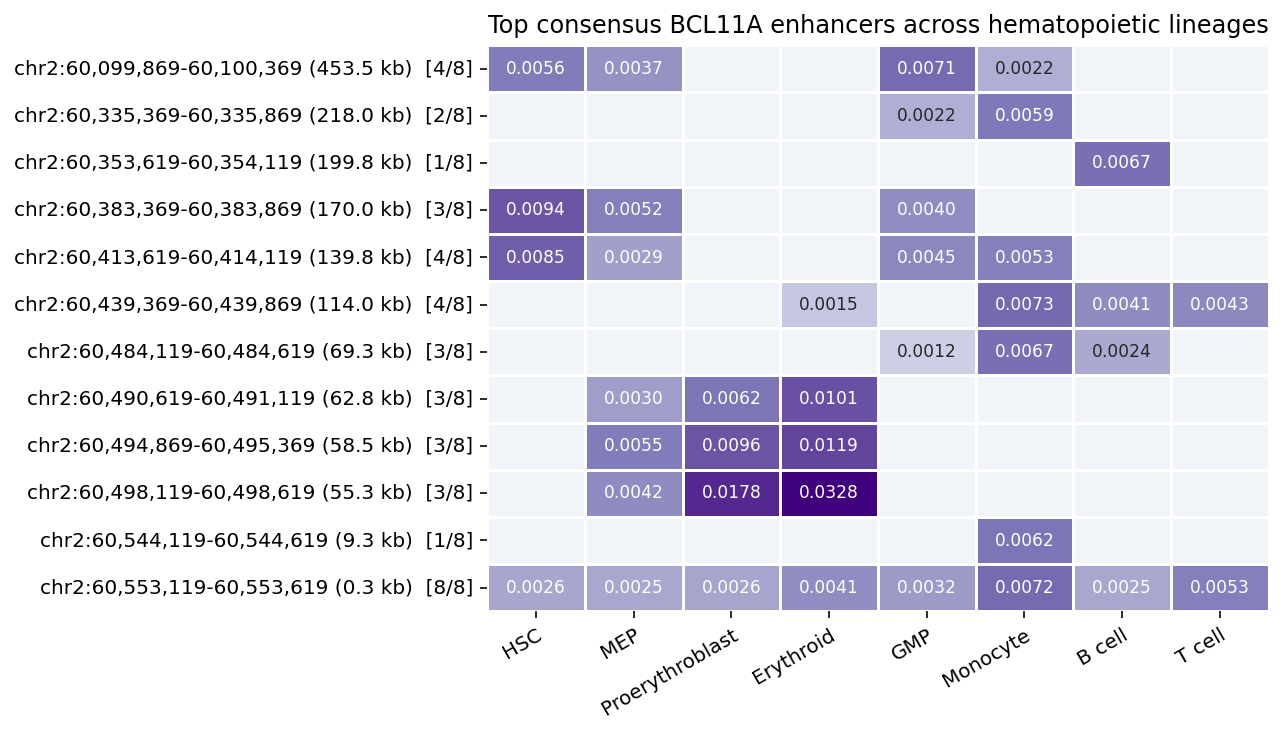

In [6]:
# @title Compare top consensus BCL11A enhancers across hematopoietic lineages
consensus_df = enhancer_scoring.assign_consensus_enhancers(enhancers_df)

n_raw = len(enhancers_df[['chromosome', 'start', 'end']].drop_duplicates())
n_consensus = len(
    consensus_df[
        ['chromosome', 'consensus_peak_start', 'consensus_peak_end']
    ].drop_duplicates()
)
print(
    f'Merged {n_raw} distinct intervals into {n_consensus} consensus peaks'
    f' across {len(lineage_labels)} lineages.'
)

biosample_to_lineage = {
    g.biosample_name: label
    for label, g in zip(lineage_labels, grad_outputs, strict=True)
}
lineage_table = (
    consensus_df.assign(
        lineage=consensus_df['biosample_name'].map(biosample_to_lineage)
    )
    .pivot_table(
        index=['chromosome', 'consensus_peak_start', 'consensus_peak_end'],
        columns='lineage',
        values='gradient_score',
        aggfunc='max',
    )
    .reindex(columns=lineage_labels)
)
subset_table = lineage_table.loc[
    lineage_table.max(axis=1).nlargest(12).index
].sort_index()
n_lineages = subset_table.notna().sum(axis=1)
scores = subset_table.to_numpy(dtype=float)
row_labels = [
    f'{chrom}:{start:,}-{end:,}'
    f' ({abs(0.5 * (start + end) - bcl11a_tss) / 1e3:.1f} kb)'
    f'  [{n}/{len(lineage_labels)}]'
    for (chrom, start, end), n in zip(
        subset_table.index, n_lineages, strict=True
    )
]
norm = mpl.colors.LogNorm(vmin=np.nanmin(scores), vmax=np.nanmax(scores))

fig, ax = plt.subplots(figsize=(9.0, 5.2))
ax.set_facecolor('#f1f5f9')
sns.heatmap(
    scores,
    cmap=arc_cmap,
    norm=norm,
    annot=True,
    fmt='.4f',
    annot_kws={'size': 8.5},
    xticklabels=lineage_labels,
    yticklabels=row_labels,
    linewidths=1.5,
    linecolor='white',
    cbar=False,
    ax=ax,
)
plt.setp(
    ax.get_xticklabels(), rotation=30, ha='right', rotation_mode='anchor'
)
ax.set_title('Top consensus BCL11A enhancers across hematopoietic lineages')
fig.tight_layout()
plt.show()

The consensus heatmap reconciles all three erythroid enhancers (`+62 kb`, `+58 kb`, and `+55 kb`, each active in `3/8` lineages along `MEP → Proerythroblast → Erythroid`), the pan-hematopoietic promoter (`8/8` lineages), stem/myeloid distal enhancers (`3/8–4/8`), and a B-cell-specific distal element at `199.8 kb` (`1/8`).

## Scoring custom candidate enhancers with `score_enhancers`

In the consensus heatmap above, lineages that fall below the calling thresholds appear in gray rather than showing continuous scores. When you already have fixed candidate cis-regulatory elements (such as experimental ATAC/DNase peaks, ENCODE cCREs, CRISPRi target regions, or deduplicated consensus intervals) and want quantitative, unthresholded scores across every condition, pass those intervals directly to `enhancer_scoring.score_enhancers`.

Below we compare the continuous E2G gradient scores of the `+62 kb`, `+58 kb`, and `+55 kb` erythroid DHS elements in Erythroid (`UBERON:0002371_CL:0000765`) versus B cell (`UBERON:0002371_CL:0000788`):

In [7]:
# @title Score candidate BCL11A enhancers in Erythroid vs B cell
b_cell_idx = lineage_labels.index('B cell')

erythroid_candidates = enhancer_scoring.score_enhancers(
    grad_outputs[erythroid_idx], canonical_erythroid_dhs
).assign(lineage='Erythroid')
b_cell_candidates = enhancer_scoring.score_enhancers(
    grad_outputs[b_cell_idx], canonical_erythroid_dhs
).assign(lineage='B cell')

pd.concat([erythroid_candidates, b_cell_candidates], ignore_index=True)[[
    'lineage',
    'name',
    'chromosome',
    'start',
    'end',
    'gradient_score',
]]

,lineage,name,chromosome,start,end,gradient_score
0,Erythroid,+62 kb,chr2,60490409,60491729,0.010165
1,Erythroid,+58 kb,chr2,60494920,60496208,0.008028
2,Erythroid,+55 kb,chr2,60497676,60498941,0.032665
3,B cell,+62 kb,chr2,60490409,60491729,0.000117
4,B cell,+58 kb,chr2,60494920,60496208,0.000173
5,B cell,+55 kb,chr2,60497676,60498941,0.000148


Although B cells also strongly express *BCL11A* (reflecting *BCL11A*'s essential role in B-lymphopoiesis), their `gradient_score` across the `+62 kb`, `+58 kb`, and `+55 kb` elements is ~45–220× lower than in Erythroid (`0.00012–0.00017` vs. `0.0080–0.0327`). Instead, B-cell *BCL11A* expression is driven by distinct B-cell-accessible distal elements (such as the region near `chr2:60.44 Mb` visible in the locus plot above), explaining why disrupting the `+55/+58/+62 kb` intronic cluster selectively derepresses fetal hemoglobin in erythroid cells while sparing B-cell function ([Bauer et al., *Science* 2013](https://doi.org/10.1126/science.1242088); [Canver et al., *Nature* 2015](https://doi.org/10.1038/nature15521)).